# Top_15 predictors

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import  matplotlib.pyplot as plt
import re
import math

In [2]:
df_final= pd.read_excel('C:/Users/pc/Documents/my_thesis/research_data/new data/final_imp.xlsx')

In [3]:
# Keep the first occurrence of each MRN and remove subsequent duplicates
df_final = df_final.drop_duplicates(
    subset="MRN",
    keep="first"
).copy()

print("Remaining records:", len(df_final))
print("Removed records:", 6309 - len(df_final))
print("Remaining duplicated MRNs:", df_final["MRN"].duplicated().sum())

Remaining records: 5515
Removed records: 794
Remaining duplicated MRNs: 0


In [4]:
clinical_limits = {
    'hr': (30, 250),
    'sbp': (50, 300),
    'dbp': (20, 180),
    'rr': (5, 80),
    'temp': (30, 45),
    'spo2': (0, 100),
    'rbs': (20, 1000),
    'Pain_score': (0, 10),
    'sodium': (100, 180),
    'potassium': (1.5, 10),
    'wbc': (0.1, 300),
    'rbc': (0.5, 10),

    'basophil': (0, 20),
    'eosinophil': (0, 40),
    'monocyte': (0, 30),
    'neutrophil': (0, 100),
    'lymphocyte': (0, 100),
    'hemoglobin': (2, 25),
    'hematocrit': (5, 80),
    'mcv': (50, 150),
    'mch': (10, 50),
    'mchc': (20, 45),
    'mpv': (5, 20),
    'plt': (5, 2000),

    'ast_sgot': (0, 5000),
    'alt_sgpt': (0, 5000),
    'creatinine': (0.1, 20),

    'oxy_use': (0, 100),
    'Age_years': (13, 120)
}

# ==========================================
# Backup Original Dataset
# ==========================================
df_original = df_final.copy()

# ==========================================
# Replace Clinical Outliers with NaN
# ==========================================
print("Replacing values outside clinical limits...\n")

for col, (low, high) in clinical_limits.items():

    outliers = (df_final[col] < low) | (df_final[col] > high)
    n_outliers = outliers.sum()

    df_final.loc[outliers, col] = np.nan

Replacing values outside clinical limits...



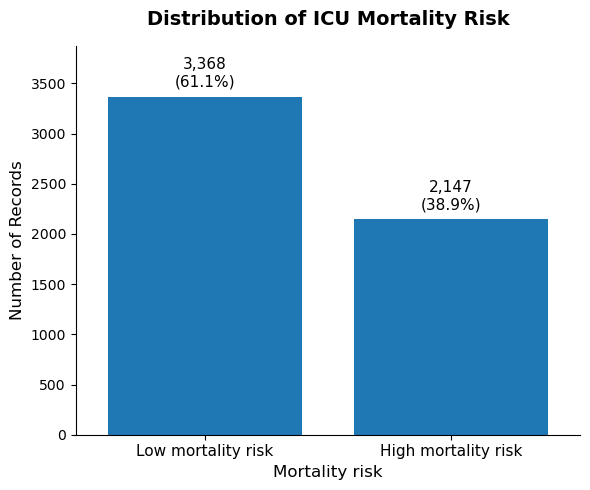

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Outcome labels
outcome = df_final["stat"].map({
    0: "low mortality risk",
    1: "High mortality risk"
})

# Counts and percentages
counts = outcome.value_counts().reindex(
    ["low mortality risk", "High mortality risk"]
)

percentages = counts / counts.sum() * 100

# Very close positions
x = np.array([0, 0.38])

fig, ax = plt.subplots(figsize=(6, 5))

# Narrow bars with very small gap
bars = ax.bar(
    x,
    counts.values,
    width=0.30
)

# Add count and percentage
for bar, count, pct in zip(bars, counts.values, percentages.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.02,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )

# X-axis
ax.set_xticks(x)
ax.set_xticklabels(
    ["Low mortality risk", "High mortality risk"],
    fontsize=11
)

ax.set_xlabel("Mortality risk", fontsize=12)
ax.set_ylabel("Number of Records", fontsize=12)

ax.set_title(
    "Distribution of ICU Mortality Risk",
    fontsize=14,
    fontweight="bold",
    pad=15
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Remove excess empty space on the sides
ax.set_xlim(-0.20, 0.58)

ax.set_ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.show()

In [6]:
df_final.rename(columns={"oxy_use": "oxygen_consumption"}, inplace=True)

In [7]:
df_final["oxygen_support"] = pd.cut(
    df_final["oxygen_consumption"],
    bins=[-float("inf"), 0, 8, 20, float("inf")],
    labels=[
        "Off oxygen",
        "Intranasal_O2_support",
        "Facemask O2_support",
        "Mechanical ventilation" ],
    right=True,
    include_lowest=True)

In [8]:

# Avoid division by zero
eps = 1e-6
# 3. Shock Index (SI)
df_final['Shock_Index'] = df_final['hr'] / (df_final['sbp'] + eps)
# Create WBC-Temperature interaction feature
df_final['WBC_Temperature_Interaction'] = df_final['wbc'] * df_final['temp']

In [9]:
# ============================================================
# REVERSE NUMERIC CODES BACK TO ORIGINAL CATEGORY NAMES
# ============================================================

# 1. Admission source
admit_reverse_map = {
    '1': 'Emergency',
    '2': 'Medical Ward',
    '3': 'Surgical Ward',
    '4': 'Pediatrics Ward',
    '5': 'Maternity Ward',
    '6': 'Orthopedic Ward',
    '7': 'HDU',
    '8': 'Other Specialty Wards'
}

df_final['Admission_source'] = (
    df_final['Admission_source']
    .astype(str)
    .replace(admit_reverse_map)
)


# 2. Diagnosis superclass
diag_reverse_map = {
    '1': 'Cardiovascular Disease',
    '2': 'Respiratory Disease',
    '3': 'Neurological Disease',
    '4': 'Sepsis / Infection',
    '5': 'Gastrointestinal / Hepatic Disease',
    '6': 'Trauma / Toxicology',
    '7': 'Endocrine / Metabolic Disease',
    '8': 'Renal Disease',
    '9': 'Thromboembolism',
    '10': 'Malignancy',
    '11': 'Multi-organ Failure',
    '12': 'Obstetric / Gynecology',
    '13': 'Autoimmune / Systemic Disease',
    '14': 'Other'
}

df_final['case_category'] = (
    df_final['case_category']
    .astype(str)
    .replace(diag_reverse_map)
)

In [10]:
# KEEP ONLY SELECTED VARIABLES FOR MACHINE LEARNING
selected_columns = [
     'dbp',
    'Shock_Index',
    'sodium',
    'potassium',
    'neutrophil',
    'lymphocyte',
    'plt',
    'rr',
    'case_category',
   'Age_years',
   'oxygen_support',
    'stat',
    'ast_sgot',
   'hemoglobin',
   'Pain_score',
   'WBC_Temperature_Interaction']
# Keep ONLY the selected columns that exist
df_final = df_final[
    [col for col in selected_columns if col in df_final.columns]
].copy()

In [11]:
from sklearn.model_selection import train_test_split

# ============================================================
# STRATIFIED 70/15/15 TRAIN–VALIDATION–TEST SPLIT
# Stratified by mortality outcome: stat
# ============================================================

random_state = 42

# 70% TRAIN, 30% remaining
train, remaining = train_test_split(
    df_final,
    test_size=0.30,
    stratify=df_final["stat"],
    random_state=random_state
)

# 15% VALIDATION, 15% TEST
validation, test = train_test_split(
    remaining,
    test_size=0.50,
    stratify=remaining["stat"],
    random_state=random_state
)

# ============================================================
# CHECK SIZES
# ============================================================

print("Dataset sizes:")
print(f"Train:      {len(train)} ({len(train)/len(df_final)*100:.2f}%)")
print(f"Validation: {len(validation)} ({len(validation)/len(df_final)*100:.2f}%)")
print(f"Test:       {len(test)} ({len(test)/len(df_final)*100:.2f}%)")

# ============================================================
# CHECK MORTALITY DISTRIBUTION
# ============================================================

for name, data in [
    ("Train", train),
    ("Validation", validation),
    ("Test", test)
]:
    print(f"\n{name}:")

    print(
        data["stat"]
        .value_counts()
        .sort_index()
        .rename(index={
            0: "low mortality risk",
            1: "High mortality risk"
        })
    )

    print(
        (data["stat"]
         .value_counts(normalize=True)
         .sort_index() * 100)
        .round(2)
        .rename(index={
            0: "low mortality risk",
            1: "High mortality risk"
        })
    )


Dataset sizes:
Train:      3860 (69.99%)
Validation: 827 (15.00%)
Test:       828 (15.01%)

Train:
stat
low mortality risk     2357
High mortality risk    1503
Name: count, dtype: int64
stat
low mortality risk     61.06
High mortality risk    38.94
Name: proportion, dtype: float64

Validation:
stat
low mortality risk     505
High mortality risk    322
Name: count, dtype: int64
stat
low mortality risk     61.06
High mortality risk    38.94
Name: proportion, dtype: float64

Test:
stat
low mortality risk     506
High mortality risk    322
Name: count, dtype: int64
stat
low mortality risk     61.11
High mortality risk    38.89
Name: proportion, dtype: float64


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
mean_impute_cols = [
     'dbp',
    'Shock_Index',
    'sodium',
    'potassium',
   'Age_years',
   'hemoglobin',
   'WBC_Temperature_Interaction']
median_impute_cols = [
    'rr',
    'neutrophil',
    'lymphocyte',
    'plt',
    'Pain_score',
    'ast_sgot']
# CATEGORICAL VARIABLES — ONE-HOT ENCODING
categorical_cols = [
    'case_category',
    'oxygen_support'
]

mean_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='mean'))
    ])
median_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ])

# CATEGORICAL IMPUTATION + ONE-HOT ENCODING

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False))  ])

# ============================================================
# COLUMN TRANSFORMER

preprocessor = ColumnTransformer(
    transformers=[
        ('mean_num', mean_transformer, mean_impute_cols),
        ('median_num', median_transformer, median_impute_cols),
        ('categorical', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

In [13]:
# 1. IMPORT LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier, plot_importance

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    brier_score_loss)
from sklearn.calibration import calibration_curve
print("Libraries imported successfully.")

Libraries imported successfully.


In [14]:
# Calculate class weight from training data only

negative_count = (train["stat"] == 0).sum()
positive_count = (train["stat"] == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Training class distribution:")
print("Class 0 (Low mortality risk):", negative_count)
print("Class 1 (High mortality risk):", positive_count)
print("Scale Pos Weight:", scale_pos_weight)

Training class distribution:
Class 0 (Low mortality risk): 2357
Class 1 (High mortality risk): 1503
Scale Pos Weight: 1.5681969394544244


In [15]:
# XGBOOST MODEL DEFINITION

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",

    # Class imbalance
    scale_pos_weight=scale_pos_weight,

    # Anti-overfitting settings
    max_depth=3,
    min_child_weight=5,
    gamma=0.3,
    subsample=0.80,
    colsample_bytree=0.80,
    learning_rate=0.05,
    reg_alpha=0.5,
    reg_lambda=5
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.3,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=5, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=-1,
              num_parallel_tree=None, ...)


In [16]:
param_distributions = {
    "n_estimators": [
        100, 150, 200, 250, 300
    ],
    "max_depth": [
        2, 3, 4
    ],
    "learning_rate": [
        0.01, 0.03, 0.05, 0.08
    ],
    "min_child_weight": [
        3, 5, 7, 10
    ],
    "gamma": [
        0.1, 0.3, 0.5, 1.0
    ],
    "subsample": [
        0.70, 0.80, 0.90
    ],
    "colsample_bytree": [
        0.60, 0.70, 0.80, 0.90
    ],
    "reg_alpha": [
        0.1, 0.5, 1.0, 2.0
    ],
    "reg_lambda": [
        2, 5, 10, 20
    ]
}

print(
    "Number of parameters being optimized:",
    len(param_distributions)
)

Number of parameters being optimized: 9


In [17]:
# ============================================================
# XGBOOST HYPERPARAMETER SEARCH
# TRAIN / VALIDATION / TEST APPROACH
# ============================================================

from itertools import product
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible parameter combinations
# ------------------------------------------------------------

param_combinations = list(product(
    param_distributions['n_estimators'],
    param_distributions['max_depth'],
    param_distributions['learning_rate'],
    param_distributions['min_child_weight'],
    param_distributions['gamma'],
    param_distributions['subsample'],
    param_distributions['colsample_bytree'],
    param_distributions['reg_alpha'],
    param_distributions['reg_lambda']
))

print("Total possible parameter combinations:", len(param_combinations))

Total possible parameter combinations: 184320


In [18]:
# ============================================================
# RANDOMLY SELECT 50 PARAMETER COMBINATIONS
# ============================================================

import random

random.seed(42)

n_iter = 50

selected_combinations = random.sample(
    param_combinations,
    n_iter
)

print("Number of parameter combinations to evaluate:", 
      len(selected_combinations))

Number of parameter combinations to evaluate: 50


In [19]:
X_train = train.drop(columns=["stat"])
y_train = train["stat"]

X_validation = validation.drop(columns=["stat"])
y_validation = validation["stat"]

X_test = test.drop(columns=["stat"])
y_test = test["stat"]

In [20]:
# ============================================================
# PREPROCESSING
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)

X_validation_processed = preprocessor.transform(X_validation)

X_test_processed = preprocessor.transform(X_test)

print("Train shape:", X_train_processed.shape)
print("Validation shape:", X_validation_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (3860, 29)
Validation shape: (827, 29)
Test shape: (828, 29)


In [21]:
# ============================================================
# XGBOOST HYPERPARAMETER EVALUATION
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score

results = []

for i, combination in enumerate(selected_combinations, start=1):

    (
        n_estimators,
        max_depth,
        learning_rate,
        min_child_weight,
        gamma,
        subsample,
        colsample_bytree,
        reg_alpha,
        reg_lambda
    ) = combination

    model = XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,

        n_estimators=n_estimators,
        max_depth=max_depth,
        learning_rate=learning_rate,
        min_child_weight=min_child_weight,
        gamma=gamma,
        subsample=subsample,
        colsample_bytree=colsample_bytree,
        reg_alpha=reg_alpha,
        reg_lambda=reg_lambda
    )

    # --------------------------------------------------------
    # Train ONLY on training data
    # --------------------------------------------------------

    model.fit(
        X_train_processed,
        y_train
    )

    # --------------------------------------------------------
    # Evaluate ONLY on validation data
    # --------------------------------------------------------

    y_validation_proba = model.predict_proba(
        X_validation_processed
    )[:, 1]

    validation_auc = roc_auc_score(
        y_validation,
        y_validation_proba
    )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    results.append({
        "n_estimators": n_estimators,
        "max_depth": max_depth,
        "learning_rate": learning_rate,
        "min_child_weight": min_child_weight,
        "gamma": gamma,
        "subsample": subsample,
        "colsample_bytree": colsample_bytree,
        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,
        "validation_roc_auc": validation_auc
    })

    print(
        f"Combination {i}/{len(selected_combinations)} "
        f"- Validation ROC-AUC: {validation_auc:.4f}"
    )

print("\nHyperparameter search completed.")

Combination 1/50 - Validation ROC-AUC: 0.9405
Combination 2/50 - Validation ROC-AUC: 0.9206
Combination 3/50 - Validation ROC-AUC: 0.9120
Combination 4/50 - Validation ROC-AUC: 0.9409
Combination 5/50 - Validation ROC-AUC: 0.8893
Combination 6/50 - Validation ROC-AUC: 0.9372
Combination 7/50 - Validation ROC-AUC: 0.9328
Combination 8/50 - Validation ROC-AUC: 0.8509
Combination 9/50 - Validation ROC-AUC: 0.9390
Combination 10/50 - Validation ROC-AUC: 0.9405
Combination 11/50 - Validation ROC-AUC: 0.9309
Combination 12/50 - Validation ROC-AUC: 0.9334
Combination 13/50 - Validation ROC-AUC: 0.8721
Combination 14/50 - Validation ROC-AUC: 0.9068
Combination 15/50 - Validation ROC-AUC: 0.9048
Combination 16/50 - Validation ROC-AUC: 0.9312
Combination 17/50 - Validation ROC-AUC: 0.9294
Combination 18/50 - Validation ROC-AUC: 0.9351
Combination 19/50 - Validation ROC-AUC: 0.9385
Combination 20/50 - Validation ROC-AUC: 0.9375
Combination 21/50 - Validation ROC-AUC: 0.9082
Combination 22/50 - Va

In [22]:
#### ============================================================
# XGBOOST HYPERPARAMETER SEARCH RESULTS
# ============================================================

xgb_results_df = pd.DataFrame(results)

xgb_results_df = xgb_results_df.sort_values(
    by="validation_roc_auc",
    ascending=False
).reset_index(drop=True)

print("\nTop 10 XGBoost Hyperparameter Combinations:")
display(xgb_results_df.head(10))


Top 10 XGBoost Hyperparameter Combinations:


,n_estimators,max_depth,learning_rate,min_child_weight,gamma,subsample,colsample_bytree,reg_alpha,reg_lambda,validation_roc_auc
0,300,4,0.08,7,0.3,0.7,0.8,0.5,5,0.942500
1,150,4,0.08,5,1.0,0.8,0.8,0.1,5,0.940902
2,250,4,0.08,10,0.5,0.7,0.9,0.5,20,0.940791
3,300,3,0.05,7,0.3,0.7,0.6,0.5,5,0.940502
4,250,4,0.05,7,0.1,0.8,0.9,0.5,2,0.940456
5,200,4,0.08,10,0.1,0.9,0.7,0.5,10,0.939893
6,300,4,0.08,10,0.3,0.8,0.8,1.0,2,0.939825
7,300,4,0.03,7,1.0,0.9,0.9,0.1,2,0.938958
8,150,4,0.08,7,1.0,0.8,0.6,1.0,10,0.938915
9,300,3,0.08,5,1.0,0.7,0.9,1.0,20,0.938749


In [23]:
# BEST XGBOOST HYPERPARAMETERS
xgb_best_row = xgb_results_df.iloc[0]
xgb_best_params = {
    "n_estimators": int(xgb_best_row["n_estimators"]),
    "max_depth": int(xgb_best_row["max_depth"]),
    "learning_rate": xgb_best_row["learning_rate"],
    "min_child_weight": int(xgb_best_row["min_child_weight"]),
    "gamma": xgb_best_row["gamma"],
    "subsample": xgb_best_row["subsample"],
    "colsample_bytree": xgb_best_row["colsample_bytree"],
    "reg_alpha": xgb_best_row["reg_alpha"],
    "reg_lambda": xgb_best_row["reg_lambda"]
}

xgb_best_val_auc = xgb_best_row["validation_roc_auc"]

print("Best XGBoost Parameters:")
for parameter, value in xgb_best_params.items():
    print(f"  {parameter}: {value}")

print(f"\nBest XGBoost Validation ROC-AUC: {xgb_best_val_auc:.4f}")

Best XGBoost Parameters:
  n_estimators: 300
  max_depth: 4
  learning_rate: 0.08
  min_child_weight: 7
  gamma: 0.3
  subsample: 0.7
  colsample_bytree: 0.8
  reg_alpha: 0.5
  reg_lambda: 5.0

Best XGBoost Validation ROC-AUC: 0.9425


In [24]:
# ============================================================
# FINAL XGBOOST MODEL — TEST SET PREDICTIONS
# ============================================================

from xgboost import XGBClassifier

# Create final XGBoost model using the best hyperparameters
xgb_final = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

# Train using training data only
xgb_final.fit(
    X_train_processed,
    y_train
)

# ------------------------------------------------------------
# Test-set probability predictions
# ------------------------------------------------------------

xgb_test_proba = xgb_final.predict_proba(
    X_test_processed
)[:, 1]

# ------------------------------------------------------------
# Convert probabilities to binary predictions
# 0 = Survived
# 1 = Died
# ------------------------------------------------------------

xgb_test_pred = (xgb_test_proba >= 0.5).astype(int)

print("Final XGBoost model trained successfully.")
print("Test predictions generated.")
print("Number of test predictions:", len(xgb_test_pred))

Final XGBoost model trained successfully.
Test predictions generated.
Number of test predictions: 828


In [25]:

# FINAL XGBOOST MODEL

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("Final XGBoost model fitted successfully.")

Final XGBoost model fitted successfully.


In [26]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist",
    scale_pos_weight=scale_pos_weight,
    **xgb_best_params
)

xgb_model.fit(
    X_train_processed,
    y_train
)

print("Final XGBoost model fitted successfully.")

Final XGBoost model fitted successfully.


In [27]:
# Binary prediction: 0 = survived, 1 = died
xgb_test_pred = xgb_model.predict(
    X_test_processed)
# Probability of death (class 1)
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed)[:, 1]
print("Test predictions generated successfully.")
print("Number of test cases:", len(xgb_test_pred))

Test predictions generated successfully.
Number of test cases: 828


In [28]:
# FINAL XGBOOST TEST PREDICTIONS AND PROBABILITIES
# Class prediction
xgb_test_pred = xgb_model.predict(
    X_test_processed
)

# Mortality probability
xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("Predictions:", len(xgb_test_pred))
print("Probabilities:", len(xgb_test_prob))

Predictions: 828
Probabilities: 828


In [29]:
# ============================================================
# FINAL XGBOOST TEST-SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

# ============================================================
# TRAINING-SET AUROC
# ============================================================

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]

xgb_train_roc_auc = roc_auc_score(
    y_train,
    xgb_train_prob
)

# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# ============================================================
# OVERALL TEST-SET PERFORMANCE
# ============================================================

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_precision = precision_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

# Recall / Sensitivity
xgb_test_recall = recall_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

# Specificity
tn, fp, fn, tp = confusion_matrix(
    y_test,
    xgb_test_pred,
    labels=[0, 1]
).ravel()

xgb_test_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else 0
)

# F1-score
xgb_test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    zero_division=0
)

# AUROC
xgb_test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)

# Brier Score
xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob
)

# ============================================================
# AUROC GAP
# ============================================================

xgb_auc_gap = (
    xgb_train_roc_auc - xgb_test_roc_auc
)

# ============================================================
# FINAL REPORT
# ============================================================

print("\nXGBoost Performance")
print("=" * 60)
print("\nOverall Test-Set Performance")
print("-" * 60)
print(f"Accuracy:        {xgb_test_accuracy:.4f}")
print(f"Precision:       {xgb_test_precision:.4f}")
print(f"Recall:          {xgb_test_recall:.4f}")
print(f"Sensitivity:     {xgb_test_recall:.4f}")
print(f"Specificity:     {xgb_test_specificity:.4f}")
print(f"F1-score:        {xgb_test_f1:.4f}")
print(f"AUROC:           {xgb_test_roc_auc:.4f}")
print(f"Brier Score:     {xgb_test_brier:.4f}")

print("\nConfusion Matrix")
print("-" * 60)
print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        xgb_test_pred,
        labels=[0, 1],
        target_names=[
            "Low mortality risk",
            "high mortality risk"
        ],
        digits=4,
        zero_division=0
    )
)


XGBoost Performance

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:        0.8370
Precision:       0.7950
Recall:          0.7826
Sensitivity:     0.7826
Specificity:     0.8715
F1-score:        0.7887
AUROC:           0.9209
Brier Score:     0.1097

Confusion Matrix
------------------------------------------------------------
True Negatives (TN):  441
False Positives (FP): 65
False Negatives (FN): 70
True Positives (TP):  252

Class-Based Test-Set Performance
------------------------------------------------------------
                     precision    recall  f1-score   support

 Low mortality risk     0.8630    0.8715    0.8673       506
high mortality risk     0.7950    0.7826    0.7887       322

           accuracy                         0.8370       828
          macro avg     0.8290    0.8271    0.8280       828
       weighted avg     0.8365    0.8370    0.8367       828



In [30]:
# ============================================================
# FINAL XGBOOST TEST-SET PERFORMANCE
# OVERALL AND CLASS-BASED METRICS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report,
    confusion_matrix
)

# ============================================================
# TRAINING-SET AUROC
# ============================================================

xgb_train_prob = xgb_model.predict_proba(
    X_train_processed
)[:, 1]

xgb_train_roc_auc = roc_auc_score(
    y_train,
    xgb_train_prob
)

# ============================================================
# TEST-SET PREDICTIONS AND PROBABILITIES
# ============================================================

xgb_test_pred = xgb_model.predict(
    X_test_processed
)

xgb_test_probs = xgb_model.predict_proba(
    X_test_processed
)

# Identify the probability column for each class
classes = xgb_model.classes_

class_0_idx = np.where(classes == 0)[0][0]
class_1_idx = np.where(classes == 1)[0][0]

xgb_test_prob_0 = xgb_test_probs[:, class_0_idx]
xgb_test_prob_1 = xgb_test_probs[:, class_1_idx]

# ============================================================
# OVERALL TEST-SET PERFORMANCE
# ============================================================

xgb_test_accuracy = accuracy_score(
    y_test,
    xgb_test_pred
)

xgb_test_precision = precision_score(
    y_test,
    xgb_test_pred,
    pos_label=1,
    zero_division=0
)

xgb_test_recall = recall_score(
    y_test,
    xgb_test_pred,
    pos_label=1,
    zero_division=0
)

xgb_test_f1 = f1_score(
    y_test,
    xgb_test_pred,
    pos_label=1,
    zero_division=0
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    xgb_test_pred,
    labels=[0, 1]
).ravel()

# Overall specificity
xgb_test_specificity = (
    tn / (tn + fp) if (tn + fp) > 0 else np.nan
)

# Overall AUROC
xgb_test_roc_auc = roc_auc_score(
    y_test,
    xgb_test_prob_1
)

# Brier score
xgb_test_brier = brier_score_loss(
    y_test,
    xgb_test_prob_1
)

# AUROC gap
xgb_auc_gap = (
    xgb_train_roc_auc - xgb_test_roc_auc
)

# ============================================================
# CLASS-BASED PERFORMANCE
# ============================================================

class_results = {}

for class_label, class_name in [
    (0, "Low mortality risk"),
    (1, "High mortality risk")
]:

    # Treat the current class as the positive class
    y_test_binary = (
        np.asarray(y_test) == class_label
    ).astype(int)

    y_pred_binary = (
        np.asarray(xgb_test_pred) == class_label
    ).astype(int)

    # Class-specific confusion matrix
    class_tn, class_fp, class_fn, class_tp = (
        confusion_matrix(
            y_test_binary,
            y_pred_binary,
            labels=[0, 1]
        ).ravel()
    )

    # Class-specific metrics
    class_accuracy = accuracy_score(
        y_test_binary,
        y_pred_binary
    )

    class_precision = precision_score(
        y_test_binary,
        y_pred_binary,
        zero_division=0
    )

    class_sensitivity = recall_score(
        y_test_binary,
        y_pred_binary,
        zero_division=0
    )

    class_specificity = (
        class_tn / (class_tn + class_fp)
        if (class_tn + class_fp) > 0
        else np.nan
    )

    class_f1 = f1_score(
        y_test_binary,
        y_pred_binary,
        zero_division=0
    )

    # AUROC for the current class
    class_prob = (
        xgb_test_prob_0
        if class_label == 0
        else xgb_test_prob_1
    )

    class_auc = (
        roc_auc_score(
            y_test_binary,
            class_prob
        )
        if len(np.unique(y_test_binary)) == 2
        else np.nan
    )

    class_results[class_name] = {
        "Accuracy": class_accuracy,
        "Precision": class_precision,
        "Sensitivity": class_sensitivity,
        "Specificity": class_specificity,
        "F1-score": class_f1,
        "AUROC": class_auc,
        "Support": int(np.sum(y_test_binary))
    }

# ============================================================
# FINAL OVERALL REPORT
# ============================================================

print("\nXGBoost Performance")
print("=" * 70)

print("\nOverall Test-Set Performance")
print("-" * 70)

print(f"Accuracy:        {xgb_test_accuracy:.4f}")
print(f"Precision:       {xgb_test_precision:.4f}")
print(f"Recall:          {xgb_test_recall:.4f}")
print(f"Sensitivity:     {xgb_test_recall:.4f}")
print(f"Specificity:     {xgb_test_specificity:.4f}")
print(f"F1-score:        {xgb_test_f1:.4f}")
print(f"AUROC:           {xgb_test_roc_auc:.4f}")
print(f"Brier Score:     {xgb_test_brier:.4f}")
print(f"Training AUROC:  {xgb_train_roc_auc:.4f}")
print(f"AUROC Gap:       {xgb_auc_gap:.4f}")

# ============================================================
# CONFUSION MATRIX
# ============================================================

print("\nConfusion Matrix")
print("-" * 70)

print(f"True Negatives (TN):  {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives (TP):  {tp}")

# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report")
print("-" * 70)

print(
    classification_report(
        y_test,
        xgb_test_pred,
        labels=[0, 1],
        target_names=[
            "Low mortality risk",
            "High mortality risk"
        ],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# CLASS-BASED METRICS TABLE
# ============================================================

class_results_df = pd.DataFrame(
    class_results
).T

print("\nClass-Based Test-Set Performance")
print("-" * 70)

print(
    class_results_df.to_string(
        float_format=lambda x: f"{x:.4f}"
    )
)


XGBoost Performance

Overall Test-Set Performance
----------------------------------------------------------------------
Accuracy:        0.8370
Precision:       0.7950
Recall:          0.7826
Sensitivity:     0.7826
Specificity:     0.8715
F1-score:        0.7887
AUROC:           0.9209
Brier Score:     0.1097
Training AUROC:  0.9838
AUROC Gap:       0.0629

Confusion Matrix
----------------------------------------------------------------------
True Negatives (TN):  441
False Positives (FP): 65
False Negatives (FN): 70
True Positives (TP):  252

Classification Report
----------------------------------------------------------------------
                     precision    recall  f1-score   support

 Low mortality risk     0.8630    0.8715    0.8673       506
High mortality risk     0.7950    0.7826    0.7887       322

           accuracy                         0.8370       828
          macro avg     0.8290    0.8271    0.8280       828
       weighted avg     0.8365    0.8370    0.

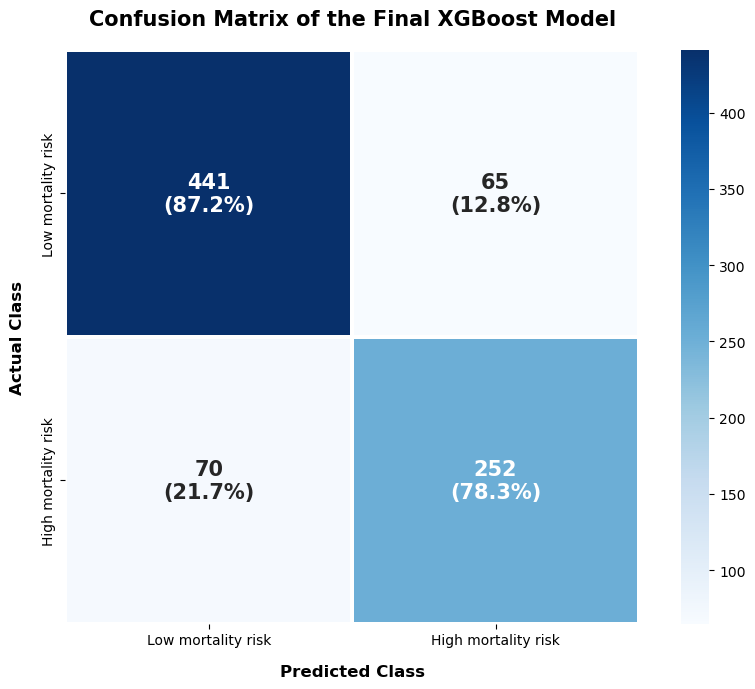

In [31]:
# ============================================================
# THESIS-READY CONFUSION MATRIX: FINAL XGBOOST MODEL
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    xgb_test_pred,
    labels=[0, 1]
)

# Calculate percentages by actual class (row-wise)
cm_percent = cm / cm.sum(axis=1, keepdims=True) * 100

# Create annotations: counts + percentages
labels = np.array([
    [
        f"{cm[i, j]:,}\n({cm_percent[i, j]:.1f}%)"
        for j in range(2)
    ]
    for i in range(2)
])

# Create figure
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    square=True,
    linewidths=1.5,
    linecolor="white",
    xticklabels=[
        "Low mortality risk",
        "High mortality risk"
    ],
    yticklabels=[
        "Low mortality risk",
        "High mortality risk"
    ],
    annot_kws={
        "size": 15,
        "weight": "bold"
    },
    ax=ax
)

# Titles and axis labels
ax.set_title(
    "Confusion Matrix of the Final XGBoost Model",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Predicted Class",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Actual Class",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()

# Save high-resolution figure for thesis
plt.savefig(
    "XGBoost_Confusion_Matrix.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# SAVE TRAINED XGBOOST MODEL
# ============================================================

import os
import joblib

# Destination folder
save_dir = r"C:\Users\pc\Downloads\manuscript"

# Create folder if it does not exist
os.makedirs(save_dir, exist_ok=True)

# Save the trained model
model_path = os.path.join(
    save_dir,
    "icu_mortality_xgboost.pkl"
)

joblib.dump(xgb_model, model_path)

print("XGBoost model saved successfully!")
print(f"Location: {model_path}")

In [34]:
import joblib
import os

save_path = (
    r"C:\Users\pc\Downloads\manuscript"
    r"\icu_mortality_preprocessor.pkl"
)

joblib.dump(preprocessor, save_path)

print("Saved fitted preprocessing object:", save_path)

Saved fitted preprocessing object: C:\Users\pc\Downloads\manuscript\icu_mortality_preprocessor.pkl


In [32]:
# ============================================================
# CLEAN SHAP FEATURE NAMES FOR DISPLAY
# ============================================================

# Get original processed feature names
feature_names_raw = preprocessor.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = (
    pd.Series(feature_names_raw)
    .str.replace("mean_num__", "", regex=False)
    .str.replace("median_num__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
    .tolist()
)

print("Cleaned feature names:")
print(feature_names)

Cleaned feature names:
['dbp', 'Shock_Index', 'sodium', 'potassium', 'Age_years', 'hemoglobin', 'WBC_Temperature_Interaction', 'rr', 'neutrophil', 'lymphocyte', 'plt', 'Pain_score', 'ast_sgot', 'case_category_Cardiovascular Disease', 'case_category_Endocrine / Metabolic Disease', 'case_category_Gastrointestinal / Hepatic Disease', 'case_category_Malignancy', 'case_category_Multi-organ Failure', 'case_category_Neurological Disease', 'case_category_Obstetric / Gynecology', 'case_category_Other', 'case_category_Renal Disease', 'case_category_Respiratory Disease', 'case_category_Sepsis / Infection', 'case_category_Thromboembolism', 'case_category_Trauma / Toxicology', 'oxygen_support_Intranasal_O2_support', 'oxygen_support_Mechanical ventilation', 'oxygen_support_Off oxygen']


SHAP values shape: (828, 29)
Test data shape: (828, 29)
Number of feature names: 29

TOP 20 SHAP FEATURES
                                         Feature  Mean_ABS_SHAP
                                          sodium       0.709716
                                       potassium       0.506414
                     WBC_Temperature_Interaction       0.410216
                                     Shock_Index       0.377775
                                      lymphocyte       0.368172
                                             dbp       0.321933
                                       Age_years       0.293851
                       oxygen_support_Off oxygen       0.291288
                                             plt       0.289690
           oxygen_support_Mechanical ventilation       0.279031
            case_category_Cardiovascular Disease       0.240517
                                      Pain_score       0.199787
                                      neutrophil       0.19937

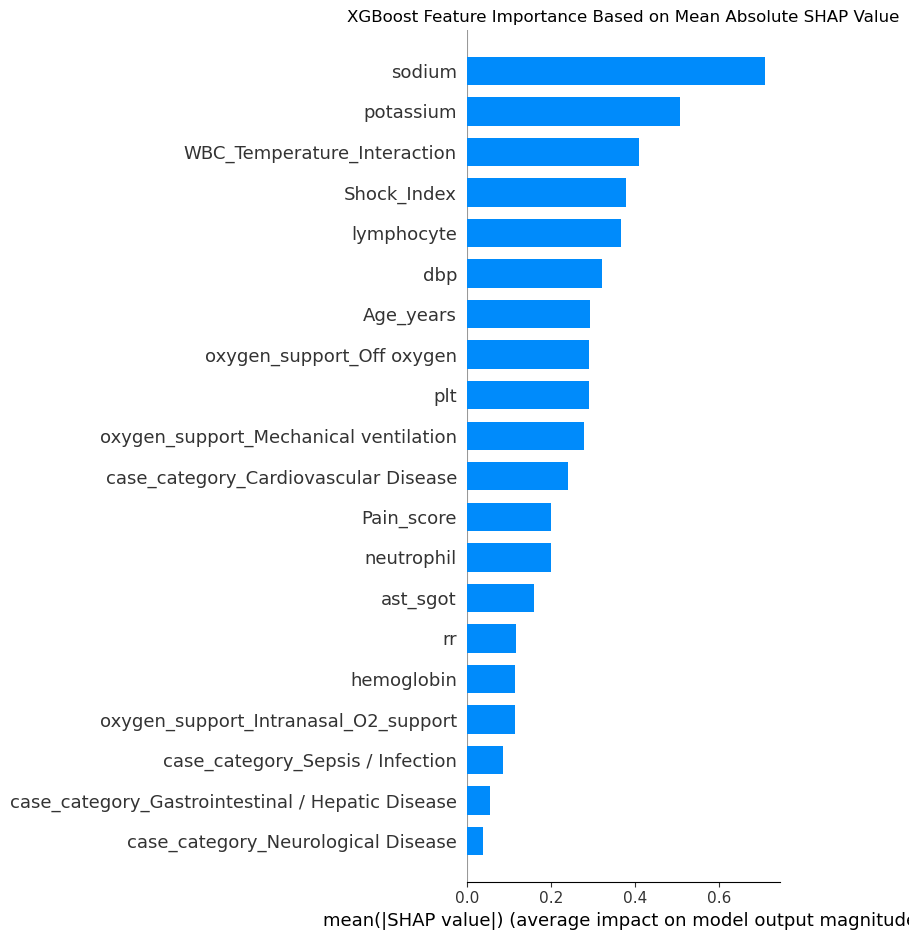

In [88]:
# ============================================================
# SHAP FEATURE IMPORTANCE — FINAL XGBOOST MODEL
# ============================================================

import shap
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create SHAP explainer
# ------------------------------------------------------------

explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values on the TEST SET
shap_values = explainer.shap_values(X_test_processed)

print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test_processed.shape)


# ------------------------------------------------------------
# 2. Get and CLEAN processed feature names
# ------------------------------------------------------------

feature_names_raw = preprocessor.get_feature_names_out()

# Remove preprocessing prefixes
feature_names = [
    name.replace("mean_num__", "")
        .replace("median_num__", "")
        .replace("categorical__", "")
    for name in feature_names_raw
]

print("Number of feature names:", len(feature_names))


# ------------------------------------------------------------
# 3. SHAP feature importance
# ------------------------------------------------------------

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_ABS_SHAP": abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_ABS_SHAP",
    ascending=False
)

print("\nTOP 20 SHAP FEATURES")
print("=" * 60)
print(shap_importance.head(20).to_string(index=False))


# ------------------------------------------------------------
# 4. SHAP BAR PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "XGBoost Feature Importance Based on Mean Absolute SHAP Value"
)

plt.tight_layout()
plt.show()

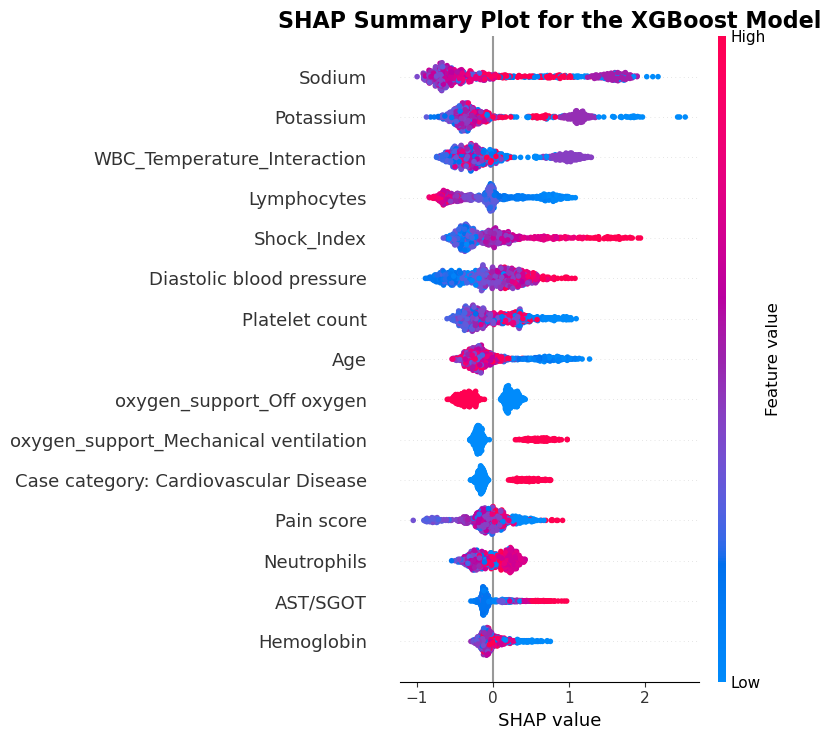

In [32]:
# ============================================================
# XGBOOST SHAP BEESWARM PLOT — TOP 15 VARIABLES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. Validation data
# ------------------------------------------------------------

X_shap = np.asarray(X_validation_processed)

# ------------------------------------------------------------
# 2. Get feature names
# ------------------------------------------------------------

feature_names = preprocessor.get_feature_names_out()

# ------------------------------------------------------------
# 3. Remove preprocessing prefixes
# ------------------------------------------------------------

feature_names = [
    str(x)
    .replace("mean_num__", "")
    .replace("median_num__", "")
    .replace("categorical__", "")
    for x in feature_names
]

# ------------------------------------------------------------
# 4. Clinical variable names
# ------------------------------------------------------------

name_map = {
    "hr": "Heart rate",
    "sbp": "Systolic blood pressure",
    "dbp": "Diastolic blood pressure",
    "temp": "Temperature",
    "spo2": "SpO₂",
    "rbs": "Random blood sugar",
    "sodium": "Sodium",
    "potassium": "Potassium",
    "neutrophil": "Neutrophils",
    "lymphocyte": "Lymphocytes",
    "plt": "Platelet count",
    "Age_years": "Age",
    "oxy_use": "Oxygen use",
    "creatinine": "Creatinine",
    "rr": "Respiratory rate",
    "ast_sgot": "AST/SGOT",
    "hemoglobin": "Hemoglobin",
    "monocyte": "Monocytes",
    "Pain_score": "Pain score",
    "wbc": "White blood cell count"
}

clean_names = []

for name in feature_names:

    if name in name_map:
        name = name_map[name]

    elif name.startswith("Admission_source_"):
        name = name.replace(
            "Admission_source_",
            "Admission source: "
        )

    elif name.startswith("case_category_"):
        name = name.replace(
            "case_category_",
            "Case category: "
        )

    clean_names.append(name)

# ------------------------------------------------------------
# 5. SHAP dataframe
# ------------------------------------------------------------

X_shap_df = pd.DataFrame(
    X_shap,
    columns=clean_names
)

# ------------------------------------------------------------
# 6. Calculate SHAP values
# ------------------------------------------------------------

explainer = shap.TreeExplainer(
    xgb_model
)

shap_values = explainer.shap_values(
    X_shap_df
)

# ------------------------------------------------------------
# 7. Handle binary classification
# ------------------------------------------------------------

if isinstance(shap_values, list):

    shap_values = shap_values[1]

elif (
    isinstance(shap_values, np.ndarray)
    and shap_values.ndim == 3
):

    shap_values = shap_values[:, :, 1]

# ------------------------------------------------------------
# 8. TOP 15 SHAP BEESWARM
# ------------------------------------------------------------

plt.figure(
    figsize=(11, 8)
)

shap.summary_plot(
    shap_values,
    X_shap_df,
    plot_type="dot",
    max_display=15,
    color_bar=True,
    show=False
)

plt.title(
    "SHAP Summary Plot for the XGBoost Model",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "SHAP value",
    fontsize=13
)

plt.tight_layout()

# ------------------------------------------------------------
# 9. Save high-resolution figure
# ------------------------------------------------------------

plt.savefig(
    "XGBoost_SHAP_Top15_Validation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "XGBoost_SHAP_Top15_Validation.pdf",
    bbox_inches="tight"
)

plt.show()


# Random forest model

In [34]:
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# RANDOM FOREST MODEL
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [35]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER SEARCH SPACE
# ============================================================

rf_param_grid = {

    'n_estimators': [
        200, 300, 500
    ],

    'max_depth': [
        5, 8, 10, 12, 15
    ],

    'min_samples_split': [
        5, 10, 15, 20
    ],

    'min_samples_leaf': [
        2, 4, 6, 8
    ],

    'max_features': [
        'sqrt', 'log2'
    ],

    'bootstrap': [
        True
    ],

    'criterion': [
        'gini', 'entropy'
    ]
}

In [36]:
# ============================================================
# 11. RANDOMIZED HYPERPARAMETER SEARCH USING VALIDATION SET
# ============================================================

import itertools
import random
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# ------------------------------------------------------------
# Generate all possible hyperparameter combinations
# ------------------------------------------------------------

rf_all_combinations = list(
    itertools.product(
        rf_param_grid['n_estimators'],
        rf_param_grid['max_depth'],
        rf_param_grid['min_samples_split'],
        rf_param_grid['min_samples_leaf'],
        rf_param_grid['max_features'],
        rf_param_grid['bootstrap'],
        rf_param_grid['criterion']
    )
)

# ------------------------------------------------------------
# Randomly select 50 combinations
# ------------------------------------------------------------

random.seed(42)

rf_sampled_combinations = random.sample(
    rf_all_combinations,
    50
)

print(
    f"Total possible combinations: "
    f"{len(rf_all_combinations):,}"
)

print(
    f"Randomly selected combinations: "
    f"{len(rf_sampled_combinations)}"
)

# ------------------------------------------------------------
# Evaluate each combination on validation set
# ------------------------------------------------------------

rf_results = []

for combination in rf_sampled_combinations:

    rf_params = {
        'n_estimators': combination[0],
        'max_depth': combination[1],
        'min_samples_split': combination[2],
        'min_samples_leaf': combination[3],
        'max_features': combination[4],
        'bootstrap': combination[5],
        'criterion': combination[6]
    }

    rf_candidate = RandomForestClassifier(
        **rf_params,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    # Train ONLY on training data
    rf_candidate.fit(
        X_train_processed,
        y_train
    )

    # Predict probabilities on validation data
    rf_val_prob_candidate = rf_candidate.predict_proba(
        X_validation_processed
    )[:, 1]

    # Validation ROC-AUC
    rf_val_auc_candidate = roc_auc_score(
        y_validation,
        rf_val_prob_candidate
    )

    rf_results.append({
        **rf_params,
        'validation_roc_auc': rf_val_auc_candidate
    })

# ------------------------------------------------------------
# Store and rank results
# ------------------------------------------------------------

rf_results_df = pd.DataFrame(
    rf_results
)

rf_results_df = rf_results_df.sort_values(
    by='validation_roc_auc',
    ascending=False
).reset_index(drop=True)

print("\nTop 10 Random Forest Hyperparameter Combinations:")
display(
    rf_results_df.head(10)
)

Total possible combinations: 960
Randomly selected combinations: 50

Top 10 Random Forest Hyperparameter Combinations:


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,criterion,validation_roc_auc
0,500,15,10,2,sqrt,True,entropy,0.925417
1,300,12,5,4,sqrt,True,entropy,0.921389
2,200,15,10,6,sqrt,True,entropy,0.919882
3,200,12,15,2,sqrt,True,entropy,0.919568
4,300,15,15,6,sqrt,True,gini,0.917428
5,200,12,15,4,sqrt,True,gini,0.916998
6,200,12,10,8,log2,True,entropy,0.916721
7,300,15,10,8,sqrt,True,gini,0.916389
8,200,15,10,8,sqrt,True,gini,0.916278
9,200,10,15,2,log2,True,entropy,0.915239


In [37]:
# ============================================================
# 12. SELECT BEST RANDOM FOREST HYPERPARAMETERS
# ============================================================

rf_best_row = rf_results_df.iloc[0]

rf_best_params = {
    'n_estimators': int(rf_best_row['n_estimators']),
    'max_depth': int(rf_best_row['max_depth']),
    'min_samples_split': int(rf_best_row['min_samples_split']),
    'min_samples_leaf': int(rf_best_row['min_samples_leaf']),
    'max_features': rf_best_row['max_features'],
    'bootstrap': bool(rf_best_row['bootstrap']),
    'criterion': rf_best_row['criterion']
}

rf_best_val_auc = rf_best_row['validation_roc_auc']

print("Random Forest — Best Validation ROC-AUC:")
print(f"{rf_best_val_auc:.4f}")

print("\nRandom Forest — Best Parameters:")
for parameter, value in rf_best_params.items():
    print(f"  {parameter}: {value}")

Random Forest — Best Validation ROC-AUC:
0.9254

Random Forest — Best Parameters:
  n_estimators: 500
  max_depth: 15
  min_samples_split: 10
  min_samples_leaf: 2
  max_features: sqrt
  bootstrap: True
  criterion: entropy


In [38]:
# ============================================================
# SELECT BEST RANDOM FOREST HYPERPARAMETERS
# ============================================================

rf_best_row = rf_results_df.iloc[0]

rf_best_params = {
    'n_estimators': int(rf_best_row['n_estimators']),
    'max_depth': int(rf_best_row['max_depth']),
    'min_samples_split': int(rf_best_row['min_samples_split']),
    'min_samples_leaf': int(rf_best_row['min_samples_leaf']),
    'max_features': rf_best_row['max_features'],
    'bootstrap': bool(rf_best_row['bootstrap']),
    'criterion': rf_best_row['criterion']
}

In [39]:
# ============================================================
# RANDOM FOREST — FINAL MODEL TRAINING
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    **rf_best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)

print("Random Forest model fitted successfully.")

Random Forest model fitted successfully.


In [40]:
# ============================================================
# RANDOM FOREST FINAL TEST-SET PERFORMANCE
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# ============================================================
# TRAIN FINAL RANDOM FOREST
# ============================================================

rf_model = RandomForestClassifier(
    **rf_best_params,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_processed,
    y_train
)


# ============================================================
# TRAINING AUROC
# ============================================================

rf_train_prob = rf_model.predict_proba(
    X_train_processed
)[:, 1]

rf_train_roc_auc = roc_auc_score(
    y_train,
    rf_train_prob
)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

rf_test_pred = rf_model.predict(
    X_test_processed
)

rf_test_prob = rf_model.predict_proba(
    X_test_processed
)[:, 1]


# ============================================================
# OVERALL TEST-SET PERFORMANCE
# ============================================================

rf_test_accuracy = accuracy_score(
    y_test,
    rf_test_pred
)

rf_test_precision = precision_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_sensitivity = recall_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_f1 = f1_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_test_roc_auc = roc_auc_score(
    y_test,
    rf_test_prob
)

rf_test_brier = brier_score_loss(
    y_test,
    rf_test_prob
)


# ============================================================
# SPECIFICITY
# ============================================================

rf_test_tn, rf_test_fp, rf_test_fn, rf_test_tp = confusion_matrix(
    y_test,
    rf_test_pred
).ravel()

rf_test_specificity = rf_test_tn / (
    rf_test_tn + rf_test_fp
)


# ============================================================
# AUROC GAP
# ============================================================

rf_auc_gap = rf_train_roc_auc - rf_test_roc_auc


# ============================================================
# FINAL REPORT
# ============================================================

print("\nRandom Forest Performance")
print("=" * 60)

print(f"Training AUROC: {rf_train_roc_auc:.4f}")
print(f"Test AUROC:     {rf_test_roc_auc:.4f}")
print(f"AUROC Gap:      {rf_auc_gap:.4f}")

print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {rf_test_accuracy:.4f}")
print(f"Precision:      {rf_test_precision:.4f}")
print(f"Sensitivity:    {rf_test_sensitivity:.4f}")
print(f"Specificity:    {rf_test_specificity:.4f}")
print(f"F1-score:       {rf_test_f1:.4f}")
print(f"Brier Score:    {rf_test_brier:.4f}")

print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


Random Forest Performance
Training AUROC: 0.9979
Test AUROC:     0.9047
AUROC Gap:      0.0933

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.8213
Precision:      0.8021
Sensitivity:    0.7174
Specificity:    0.8874
F1-score:       0.7574
Brier Score:    0.1285

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.8315    0.8874    0.8585       506
        Died     0.8021    0.7174    0.7574       322

    accuracy                         0.8213       828
   macro avg     0.8168    0.8024    0.8079       828
weighted avg     0.8200    0.8213    0.8192       828



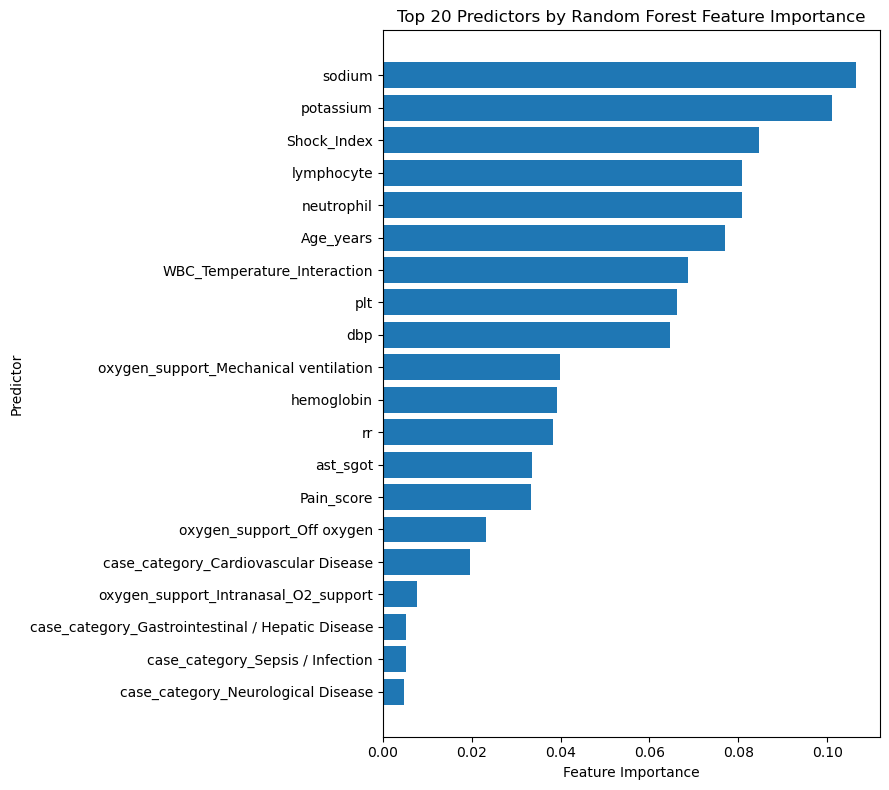

In [66]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE — TOP 20
# ORIGINAL PREDICTOR NAMES ONLY
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. GET FEATURE NAMES AND RANDOM FOREST IMPORTANCE
# ------------------------------------------------------------

rf_feature_names = preprocessor.get_feature_names_out()
rf_importances = rf_model.feature_importances_

rf_feature_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
})

# ------------------------------------------------------------
# 2. REMOVE PREPROCESSING PREFIXES
#    Examples:
#    mean_num__temp       -> temp
#    median_num__hr       -> hr
#    cat__Admission_source_Emergency -> Admission_source_Emergency
# ------------------------------------------------------------

rf_feature_importance_df["Feature"] = (
    rf_feature_importance_df["Feature"]
    .str.split("__", n=1)
    .str[-1]
)

# ------------------------------------------------------------
# 3. COMBINE ONE-HOT CATEGORIES INTO ORIGINAL PREDICTOR
# ------------------------------------------------------------

rf_categorical_features = [
    "oxy_use",
    "Admission_source",
    "diag_superclass"
]

for variable in rf_categorical_features:

    rf_feature_importance_df.loc[
        rf_feature_importance_df["Feature"].str.startswith(
            variable + "_"
        ),
        "Feature"
    ] = variable

# ------------------------------------------------------------
# 4. COMBINE IMPORTANCE FOR EACH ORIGINAL PREDICTOR
# ------------------------------------------------------------

rf_feature_importance_df = (
    rf_feature_importance_df
    .groupby("Feature", as_index=False)["Importance"]
    .sum()
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. SELECT TOP 20 PREDICTORS
# ------------------------------------------------------------

rf_top20 = (
    rf_feature_importance_df
    .head(20)
    .sort_values(
        "Importance",
        ascending=True
    )
)
# ------------------------------------------------------------
# 6. PLOT
# ------------------------------------------------------------

plt.figure(figsize=(9, 8))

plt.barh(
    rf_top20["Feature"],
    rf_top20["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Predictor")

plt.title(
    "Top 20 Predictors by Random Forest Feature Importance"
)

plt.tight_layout()
plt.show()

# Suport Vector Machine(SVM and logistic regresion

In [41]:
from sklearn.preprocessing import StandardScaler

# ============================================================
# STANDARDIZATION FOR SVM AND LOGISTIC REGRESSION
# ============================================================

# Initialize scaler
scaler = StandardScaler()

# ------------------------------------------------------------
# 1. FIT SCALER ONLY ON TRAINING DATA
# ------------------------------------------------------------
X_train_scaled = scaler.fit_transform(X_train_processed)

# ------------------------------------------------------------
# 2. APPLY TRAINING-LEARNED SCALER TO VALIDATION DATA
# ------------------------------------------------------------
X_validation_scaled = scaler.transform(X_validation_processed)

# ------------------------------------------------------------
# 3. APPLY TRAINING-LEARNED SCALER TO TEST DATA
# ------------------------------------------------------------
X_test_scaled = scaler.transform(X_test_processed)

# ============================================================
# CHECK SHAPES
# ============================================================

print("Standardized dataset shapes:")
print("-" * 45)
print("Training   :", X_train_scaled.shape)
print("Validation :", X_validation_scaled.shape)
print("Test       :", X_test_scaled.shape)

Standardized dataset shapes:
---------------------------------------------
Training   : (3860, 29)
Validation : (827, 29)
Test       : (828, 29)


In [42]:
# ============================================================
# SUPPORT VECTOR MACHINE (SVM) — MODEL DEFINITION
# ============================================================

from sklearn.svm import SVC

svm_model = SVC(
    probability=True,
    class_weight='balanced',
    random_state=42
)

print(svm_model)

SVC(class_weight='balanced', probability=True, random_state=42)


In [43]:
# ============================================================
# SVM — HYPERPARAMETER SEARCH SPACE
# ============================================================

svm_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ],

    'gamma': [
        'scale',
        0.001,
        0.01,
        0.1,
        1
    ],

    'kernel': [
        'rbf'
    ]
}

print("SVM hyperparameter search space:")
print(svm_param_grid)

SVM hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01, 0.1, 1], 'kernel': ['rbf']}


In [44]:

from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from itertools import product

In [45]:
# ============================================================
# SVM — HYPERPARAMETER TUNING USING VALIDATION SET
# ============================================================




# ============================================================
# 1. GENERATE PARAMETER COMBINATIONS
# ============================================================

param_combinations = list(product(
    svm_param_grid['C'],
    svm_param_grid['gamma'],
    svm_param_grid['kernel']
))


# ============================================================
# 2. EVALUATE EACH COMBINATION
# ============================================================

svm_results = []

for C, gamma, kernel in param_combinations:

    svm_candidate = SVC(
        C=C,
        gamma=gamma,
        kernel=kernel,
        probability=True,
        class_weight='balanced',
        random_state=42
    )

    # Fit ONLY on training data
    svm_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = svm_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    svm_results.append({
        'C': C,
        'gamma': gamma,
        'kernel': kernel,
        'Validation_ROC_AUC': validation_auc
    })


# ============================================================
# 3. RESULTS TABLE
# ============================================================

svm_results_df = pd.DataFrame(svm_results)

svm_results_df = svm_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)


print("SVM hyperparameter tuning results:")
print(svm_results_df)


# ============================================================
# 4. BEST HYPERPARAMETERS
# ============================================================

best_svm_params = svm_results_df.iloc[0].to_dict()

print("\nBest SVM hyperparameters:")
print("C     :", best_svm_params['C'])
print("gamma :", best_svm_params['gamma'])
print("kernel:", best_svm_params['kernel'])
print("Validation ROC-AUC:", best_svm_params['Validation_ROC_AUC'])

SVM hyperparameter tuning results:
         C  gamma kernel  Validation_ROC_AUC
0   100.00  0.001    rbf            0.858527
1     1.00   0.01    rbf            0.857749
2    10.00   0.01    rbf            0.854000
3     1.00  scale    rbf            0.850231
4    10.00  0.001    rbf            0.846744
5     0.10  scale    rbf            0.843804
6     0.10   0.01    rbf            0.838740
7     1.00    0.1    rbf            0.836240
8   100.00   0.01    rbf            0.832667
9     1.00  0.001    rbf            0.831283
10    0.10    0.1    rbf            0.829635
11   10.00  scale    rbf            0.824669
12    0.01   0.01    rbf            0.814547
13    0.10  0.001    rbf            0.813858
14    0.01  scale    rbf            0.812742
15    0.01  0.001    rbf            0.810676
16    0.01    0.1    rbf            0.802737
17   10.00    0.1    rbf            0.798530
18  100.00  scale    rbf            0.773778
19  100.00    0.1    rbf            0.770829
20    1.00      1   

In [47]:
# ============================================================
# SVM — FINAL MODEL WITH BEST HYPERPARAMETERS
# ============================================================

from sklearn.svm import SVC

# Get best parameters
best_C = svm_results_df.loc[0, 'C']
best_gamma = svm_results_df.loc[0, 'gamma']
best_kernel = svm_results_df.loc[0, 'kernel']

# Create final SVM
svm_final_model = SVC(
    C=best_C,
    gamma=best_gamma,
    kernel=best_kernel,
    probability=True,
    class_weight='balanced',
    random_state=42
)

# ============================================================
# FIT FINAL SVM ON TRAINING DATA
# ============================================================
svm_final_model.fit(
    X_train_scaled,
    y_train
)

print("Final SVM model fitted successfully.")
print("Best C     :", best_C)
print("Best gamma :", best_gamma)
print("Best kernel:", best_kernel)

Final SVM model fitted successfully.
Best C     : 100.0
Best gamma : 0.001
Best kernel: rbf


In [48]:
# ============================================================
# SVM — FINAL TEST PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    classification_report
)

import math


# ============================================================
# TRAINING-SET AUROC
# ============================================================

svm_train_prob = svm_final_model.predict_proba(
    X_train_scaled
)[:, 1]

svm_train_roc_auc = roc_auc_score(
    y_train,
    svm_train_prob
)


# ============================================================
# TEST PREDICTIONS
# ============================================================

y_test_pred = svm_final_model.predict(
    X_test_scaled
)

y_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# TEST-SET METRICS
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_test_pred
)

precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

# Recall = Sensitivity
sensitivity = recall

f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_test_prob
)


# ============================================================
# BRIER SCORE
# ============================================================

brier_score = brier_score_loss(
    y_test,
    y_test_prob
)


# ============================================================
# AUROC GAP
# ============================================================

auc_gap = svm_train_roc_auc - roc_auc


# ============================================================
# SPECIFICITY
# ============================================================

from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred
).ravel()

specificity = tn / (tn + fp)


# ============================================================
# DISPLAY FORMATTING
# ============================================================

def round_up_if_needed(value):
    return math.ceil(value * 100) / 100

def truncate_2_decimals(value):
    return math.floor(value * 100) / 100


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\nSVM Performance")
print("=" * 60)

print(f"Training AUROC: {svm_train_roc_auc:.4f}")
print(f"Test AUROC:     {roc_auc:.4f}")
print(f"AUROC Gap:      {auc_gap:.4f}")


print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {round_up_if_needed(accuracy):.2f}")
print(f"Precision:      {round_up_if_needed(precision):.2f}")
print(f"Sensitivity:    {round_up_if_needed(sensitivity):.2f}")
print(f"Specificity:    {round_up_if_needed(specificity):.2f}")
print(f"F1-score:       {round_up_if_needed(f1):.2f}")
print(f"Brier Score:    {truncate_2_decimals(brier_score):.2f}")


print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


SVM Performance
Training AUROC: 0.8608
Test AUROC:     0.8365
AUROC Gap:      0.0242

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.77
Precision:      0.69
Sensitivity:    0.73
Specificity:    0.79
F1-score:       0.71
Brier Score:    0.15

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.8189    0.7866    0.8024       506
        Died     0.6842    0.7267    0.7048       322

    accuracy                         0.7633       828
   macro avg     0.7516    0.7566    0.7536       828
weighted avg     0.7665    0.7633    0.7645       828



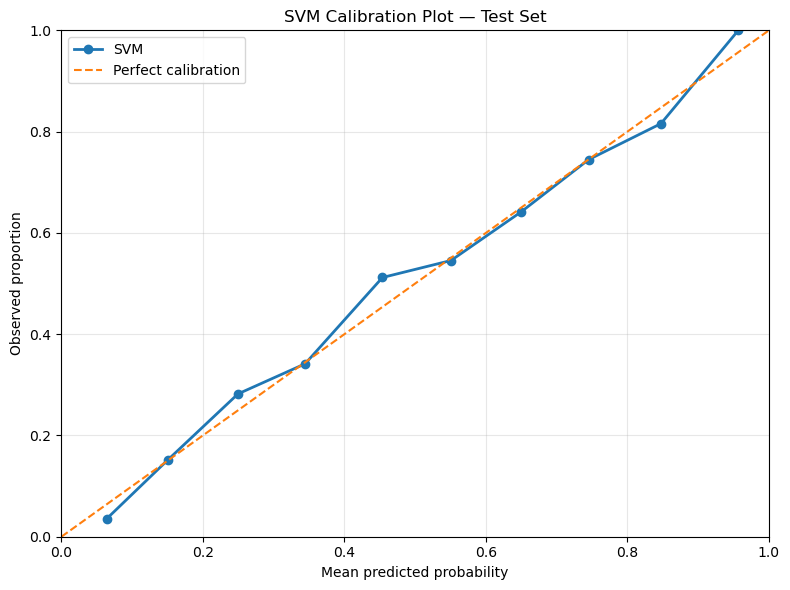

In [49]:
# ============================================================
# SVM — TEST SET CALIBRATION PLOT
# ============================================================

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Test predicted probabilities
y_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10,
    strategy='uniform'
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2,
    label='SVM'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    linewidth=1.5,
    label='Perfect calibration'
)

plt.xlabel('Mean predicted probability')
plt.ylabel('Observed proportion')
plt.title('SVM Calibration Plot — Test Set')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

# logistic regresion

In [50]:
# ============================================================
# LOGISTIC REGRESSION — MODEL DEFINITION
# ============================================================

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

print(logreg)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                   solver='liblinear')


In [51]:
# ============================================================
# LOGISTIC REGRESSION — FIT MODEL ON TRAINING DATA
# ============================================================

logreg.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


# logistic regresion

In [52]:
# ============================================================
# LOGISTIC REGRESSION — MODEL DEFINITION
# ============================================================

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

print(logreg)

LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42,
                   solver='liblinear')


In [53]:
# ============================================================
# LOGISTIC REGRESSION — FIT MODEL ON TRAINING DATA
# ============================================================

logreg.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model fitted successfully.")

Logistic Regression model fitted successfully.


In [54]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER SEARCH SPACE
# ============================================================

logreg_param_grid = {
    'C': [
        0.01,
        0.1,
        1,
        10,
        100
    ]
}

print("Logistic Regression hyperparameter search space:")
print(logreg_param_grid)

Logistic Regression hyperparameter search space:
{'C': [0.01, 0.1, 1, 10, 100]}


In [55]:
# ============================================================
# LOGISTIC REGRESSION — HYPERPARAMETER OPTIMIZATION
#              TRAIN → VALIDATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import pandas as pd

logreg_results = []

for C_value in logreg_param_grid['C']:

    logreg_candidate = LogisticRegression(
        penalty='l2',
        solver='liblinear',
        C=C_value,
        class_weight='balanced',
        max_iter=2000,
        random_state=42
    )

    # Fit on training data
    logreg_candidate.fit(
        X_train_scaled,
        y_train
    )

    # Predict probabilities on validation data
    y_validation_prob = logreg_candidate.predict_proba(
        X_validation_scaled
    )[:, 1]

    # Validation ROC-AUC
    validation_auc = roc_auc_score(
        y_validation,
        y_validation_prob
    )

    logreg_results.append({
        'C': C_value,
        'Validation_ROC_AUC': validation_auc
    })

# Convert results to DataFrame
logreg_results_df = pd.DataFrame(logreg_results)

# Rank by validation ROC-AUC
logreg_results_df = logreg_results_df.sort_values(
    by='Validation_ROC_AUC',
    ascending=False
).reset_index(drop=True)

print("Logistic Regression hyperparameter tuning results:")
print(logreg_results_df)

# Best hyperparameter
best_logreg_C = logreg_results_df.loc[0, 'C']

print("\nBest Logistic Regression hyperparameter:")
print("C:", best_logreg_C)
print(
    "Validation ROC-AUC:",
    f"{logreg_results_df.loc[0, 'Validation_ROC_AUC']:.4f}"
)

Logistic Regression hyperparameter tuning results:
        C  Validation_ROC_AUC
0    0.10            0.829906
1    1.00            0.829728
2   10.00            0.829721
3  100.00            0.829697
4    0.01            0.829598

Best Logistic Regression hyperparameter:
C: 0.1
Validation ROC-AUC: 0.8299


In [56]:
# ============================================================
# LOGISTIC REGRESSION — CREATE AND FIT BEST MODEL
# ============================================================

from sklearn.linear_model import LogisticRegression

best_logreg = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=best_logreg_C,
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

# Fit best model on training data
best_logreg.fit(
    X_train_scaled,
    y_train
)

print("Best Logistic Regression model fitted successfully.")
print("Best C:", best_logreg_C)

Best Logistic Regression model fitted successfully.
Best C: 0.1


In [57]:
# ============================================================
# LOGISTIC REGRESSION — VALIDATION SET PREDICTIONS
# ============================================================

logreg_validation_y_pred = best_logreg.predict(
    X_validation_scaled
)

# Probability of mortality
logreg_validation_y_prob = best_logreg.predict_proba(
    X_validation_scaled
)[:, 1]

print("Validation predictions generated successfully.")

Validation predictions generated successfully.


In [58]:
# ============================================================
# LOGISTIC REGRESSION — FINAL TEST SET PERFORMANCE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)


# ============================================================
# TRAINING-SET AUROC
# ============================================================

logreg_train_y_prob = best_logreg.predict_proba(
    X_train_scaled
)[:, 1]

logreg_train_roc_auc = roc_auc_score(
    y_train,
    logreg_train_y_prob
)


# ============================================================
# TEST-SET PREDICTIONS
# ============================================================

logreg_test_y_pred = best_logreg.predict(
    X_test_scaled
)

logreg_test_y_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]


# ============================================================
# TEST-SET METRICS
# ============================================================

test_accuracy = accuracy_score(
    y_test,
    logreg_test_y_pred
)

test_precision = precision_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)

# Sensitivity = Recall
test_sensitivity = test_recall


# ============================================================
# SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test,
    logreg_test_y_pred
).ravel()

test_specificity = tn / (tn + fp)


# ============================================================
# F1-SCORE
# ============================================================

test_f1 = f1_score(
    y_test,
    logreg_test_y_pred,
    zero_division=0
)


# ============================================================
# TEST ROC-AUC
# ============================================================

test_roc_auc = roc_auc_score(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# BRIER SCORE — TEST SET
# ============================================================

test_brier_score = brier_score_loss(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# AUROC GAP
# ============================================================

logreg_auc_gap = (
    logreg_train_roc_auc - test_roc_auc
)


# ============================================================
# FINAL RESULTS
# ============================================================

print("\nLogistic Regression Performance")
print("=" * 60)

print(f"Training AUROC: {logreg_train_roc_auc:.4f}")
print(f"Test AUROC:     {test_roc_auc:.4f}")
print(f"AUROC Gap:      {logreg_auc_gap:.4f}")


print("\nOverall Test-Set Performance")
print("-" * 60)

print(f"Accuracy:       {test_accuracy:.4f}")
print(f"Precision:      {test_precision:.4f}")
print(f"Sensitivity:    {test_sensitivity:.4f}")
print(f"Specificity:    {test_specificity:.4f}")
print(f"F1-score:       {test_f1:.4f}")
print(f"Brier Score:    {test_brier_score:.4f}")


print("\nClass-Based Test-Set Performance")
print("-" * 60)

print(
    classification_report(
        y_test,
        logreg_test_y_pred,
        target_names=["Survived", "Died"],
        digits=4,
        zero_division=0
    )
)


Logistic Regression Performance
Training AUROC: 0.8174
Test AUROC:     0.8133
AUROC Gap:      0.0041

Overall Test-Set Performance
------------------------------------------------------------
Accuracy:       0.7391
Precision:      0.6440
Sensitivity:    0.7360
Specificity:    0.7411
F1-score:       0.6870
Brier Score:    0.1756

Class-Based Test-Set Performance
------------------------------------------------------------
              precision    recall  f1-score   support

    Survived     0.8152    0.7411    0.7764       506
        Died     0.6440    0.7360    0.6870       322

    accuracy                         0.7391       828
   macro avg     0.7296    0.7386    0.7317       828
weighted avg     0.7486    0.7391    0.7416       828



In [59]:
# ============================================================
# SAVE SVM TEST-SET METRICS WITH EXPLICIT NAMES
# ============================================================

svm_test_accuracy = accuracy
svm_test_precision = precision
svm_test_sensitivity = sensitivity
svm_test_specificity = specificity
svm_test_f1 = f1
svm_test_roc_auc = roc_auc
svm_test_brier = brier_score
# ============================================================
# SVM — SAVE TEST PROBABILITIES WITH MODEL-SPECIFIC NAME
# ============================================================

svm_test_prob = svm_final_model.predict_proba(
    X_test_scaled
)[:, 1]

# Model comparision

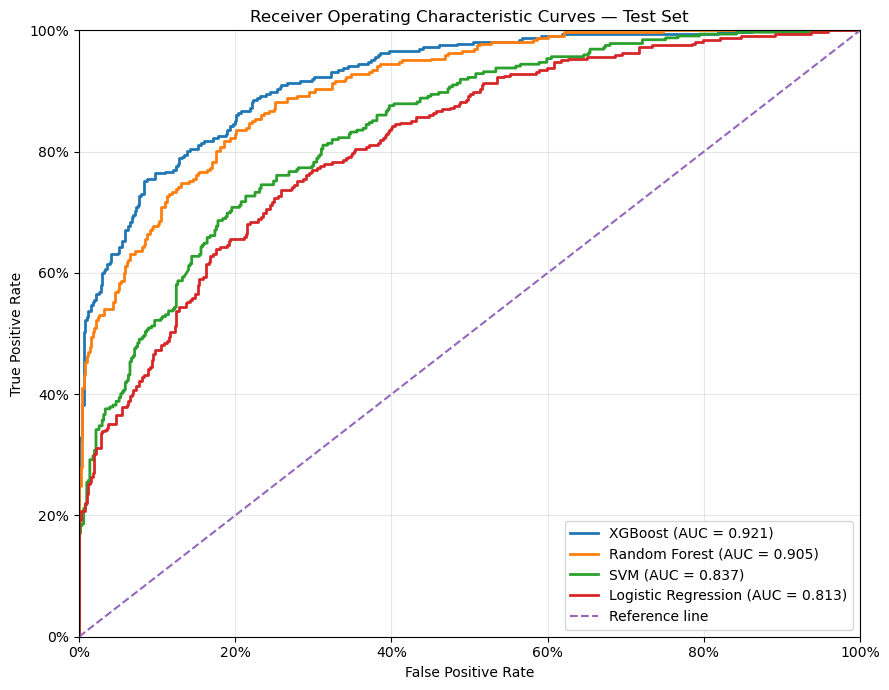

In [86]:
# ============================================================
# TEST-SET ROC CURVES — ALL FOUR FINAL MODELS
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from matplotlib.ticker import PercentFormatter


# ============================================================
# XGBOOST
# ============================================================

xgb_fpr, xgb_tpr, _ = roc_curve(
    y_test,
    xgb_test_prob
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_test_prob
)


# ============================================================
# RANDOM FOREST
# ============================================================

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_test_prob
)

rf_auc = roc_auc_score(
    y_test,
    rf_test_prob
)


# ============================================================
# SVM
# ============================================================

svm_fpr, svm_tpr, _ = roc_curve(
    y_test,
    y_test_prob
)

svm_auc = roc_auc_score(
    y_test,
    y_test_prob
)


# ============================================================
# LOGISTIC REGRESSION
# ============================================================

lr_fpr, lr_tpr, _ = roc_curve(
    y_test,
    logreg_test_y_prob
)

lr_auc = roc_auc_score(
    y_test,
    logreg_test_y_prob
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    rf_fpr,
    rf_tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    svm_fpr,
    svm_tpr,
    linewidth=2,
    label=f"SVM (AUC = {svm_auc:.3f})"
)

plt.plot(
    lr_fpr,
    lr_tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_auc:.3f})"
)


# ============================================================
# REFERENCE LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Reference line"
)


# ============================================================
# 0–100% AXES
# ============================================================

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.gca().xaxis.set_major_formatter(
    PercentFormatter(1)
)

plt.gca().yaxis.set_major_formatter(
    PercentFormatter(1)
)


# ============================================================
# LABELS
# ============================================================

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "Receiver Operating Characteristic Curves — Test Set"
)

plt.legend(
    loc="lower right"
)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



TEST-SET SAMPLE SIZE CHECK
Test outcomes: 828
XGBoost: 828
Random Forest: 828
SVM: 828
Logistic Regression: 828

All test-set probability lengths are correct.


INDEPENDENT TEST-SET CALIBRATION PERFORMANCE
              Model  Brier score  Calibration intercept  Calibration slope
            XGBoost        0.110                 -0.200              1.034
      Random Forest        0.129                  0.076              1.826
                SVM        0.158                  0.062              1.053
Logistic Regression        0.176                 -0.469              1.042


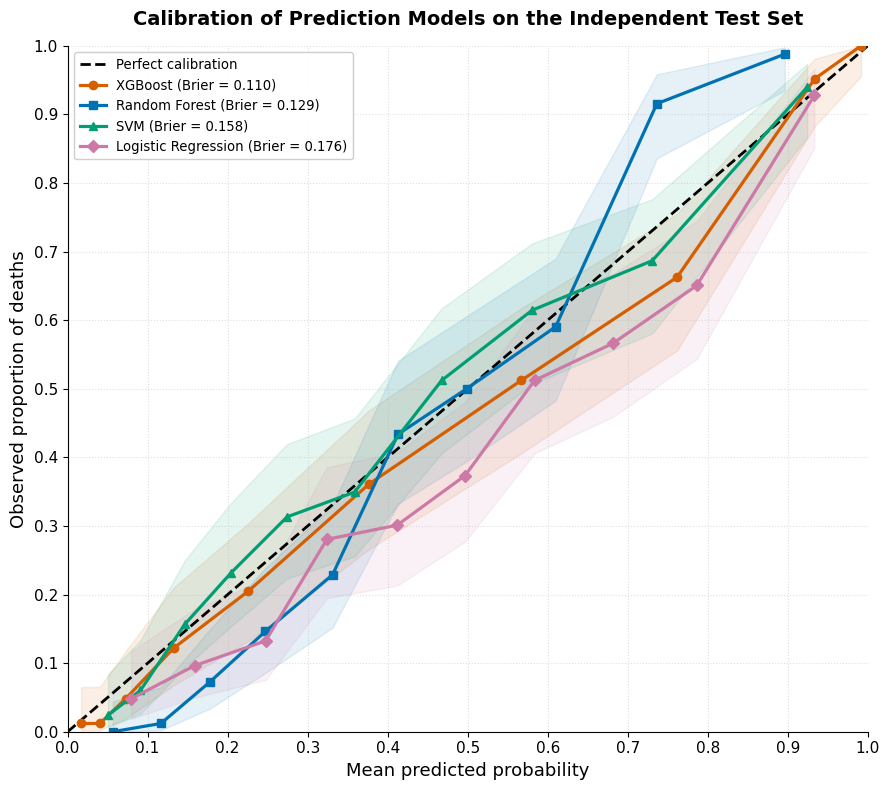

In [87]:
# ============================================================
# TEST-SET CALIBRATION
# FOUR MODELS
#
# XGBoost
# Random Forest
# SVM
# Logistic Regression
#
# RAW / UNCALIBRATED TEST PROBABILITIES
# 10 QUANTILE-BASED BINS
# BRIER SCORE
# CALIBRATION INTERCEPT
# CALIBRATION SLOPE
# 95% CI
# THESIS / PUBLICATION QUALITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss

from scipy.stats import norm
from scipy.special import expit
from scipy.optimize import minimize


# ============================================================
# 1. FUNCTION: CALIBRATION INTERCEPT AND SLOPE
# ============================================================

def calibration_intercept_slope(y_true, predicted_prob):

    y_true = np.asarray(y_true)
    predicted_prob = np.asarray(predicted_prob)

    # Avoid log(0) and log(1)
    predicted_prob = np.clip(
        predicted_prob,
        1e-6,
        1 - 1e-6
    )

    # Convert predicted probability to log-odds
    logit_pred = np.log(
        predicted_prob / (1 - predicted_prob)
    )

    # --------------------------------------------------------
    # Logistic calibration model
    #
    # logit(observed risk)
    # =
    # intercept + slope × logit(predicted risk)
    # --------------------------------------------------------

    def negative_log_likelihood(params):

        intercept = params[0]
        slope = params[1]

        linear_predictor = (
            intercept +
            slope * logit_pred
        )

        probability = expit(
            linear_predictor
        )

        probability = np.clip(
            probability,
            1e-10,
            1 - 1e-10
        )

        log_likelihood = (
            y_true * np.log(probability)
            +
            (1 - y_true) *
            np.log(1 - probability)
        )

        return -np.sum(log_likelihood)

    result = minimize(
        negative_log_likelihood,
        x0=[0.0, 1.0],
        method="BFGS"
    )

    intercept = result.x[0]
    slope = result.x[1]

    return intercept, slope


# ============================================================
# 2. FUNCTION: CALIBRATION CURVE WITH 95% CI
# ============================================================

def calibration_with_ci(
    y_true,
    predicted_prob,
    n_bins=10
):

    y_true = np.asarray(y_true)
    predicted_prob = np.asarray(predicted_prob)

    # --------------------------------------------------------
    # Quantile-based bins
    # --------------------------------------------------------

    quantiles = np.linspace(
        0,
        1,
        n_bins + 1
    )

    bin_edges = np.quantile(
        predicted_prob,
        quantiles
    )

    # Remove duplicate bin boundaries
    bin_edges = np.unique(
        bin_edges
    )

    # Assign observations to bins
    bin_index = np.digitize(
        predicted_prob,
        bin_edges[1:-1],
        right=True
    )

    mean_predicted = []
    observed_fraction = []
    lower_ci = []
    upper_ci = []
    sample_size = []

    # --------------------------------------------------------
    # Calculate each bin
    # --------------------------------------------------------

    for i in range(
        len(bin_edges) - 1
    ):

        mask = (
            bin_index == i
        )

        n = np.sum(mask)

        if n == 0:
            continue

        y_bin = y_true[mask]
        p_bin = predicted_prob[mask]

        observed = np.mean(
            y_bin
        )

        predicted = np.mean(
            p_bin
        )

        # ----------------------------------------------------
        # Wilson 95% confidence interval
        # ----------------------------------------------------

        z = norm.ppf(
            0.975
        )

        denominator = (
            1 +
            z**2 / n
        )

        centre = (
            observed +
            z**2 / (2 * n)
        ) / denominator

        margin = (
            z *
            np.sqrt(
                (
                    observed *
                    (1 - observed)
                    / n
                )
                +
                z**2 /
                (4 * n**2)
            )
            / denominator
        )

        lower = max(
            0,
            centre - margin
        )

        upper = min(
            1,
            centre + margin
        )

        mean_predicted.append(
            predicted
        )

        observed_fraction.append(
            observed
        )

        lower_ci.append(
            lower
        )

        upper_ci.append(
            upper
        )

        sample_size.append(
            n
        )

    return (
        np.array(mean_predicted),
        np.array(observed_fraction),
        np.array(lower_ci),
        np.array(upper_ci),
        np.array(sample_size)
    )


# ============================================================
# 3. DEFINE TEST-SET MODEL PROBABILITIES
# ============================================================

models = {

    "XGBoost": {
        "probability": xgb_test_prob,
        "color": "#D55E00",
        "marker": "o"
    },

    "Random Forest": {
        "probability": rf_test_prob,
        "color": "#0072B2",
        "marker": "s"
    },

    "SVM": {
        "probability": svm_test_prob,
        "color": "#009E73",
        "marker": "^"
    },

    "Logistic Regression": {
        "probability": logreg_test_y_prob,
        "color": "#CC79A7",
        "marker": "D"
    }
}


# ============================================================
# 4. CHECK SAMPLE SIZES
# ============================================================

print("\n")
print("=" * 80)
print("TEST-SET SAMPLE SIZE CHECK")
print("=" * 80)

print(
    "Test outcomes:",
    len(y_test)
)

for model_name, settings in models.items():

    print(
        model_name + ":",
        len(settings["probability"])
    )

print("=" * 80)


# ============================================================
# 5. VERIFY SAMPLE SIZES
# ============================================================

for model_name, settings in models.items():

    if len(settings["probability"]) != len(y_test):

        raise ValueError(
            model_name +
            " probability length does not match y_test."
        )


print(
    "\nAll test-set probability lengths are correct."
)


# ============================================================
# 6. CALCULATE CALIBRATION RESULTS
# ============================================================

results = []
curves = {}


for model_name, settings in models.items():

    probability = np.asarray(
        settings["probability"]
    )

    # --------------------------------------------------------
    # Brier score
    # --------------------------------------------------------

    brier = brier_score_loss(
        y_test,
        probability
    )

    # --------------------------------------------------------
    # Calibration intercept and slope
    # --------------------------------------------------------

    intercept, slope = calibration_intercept_slope(
        y_test,
        probability
    )

    # --------------------------------------------------------
    # Calibration curve
    # --------------------------------------------------------

    (
        mean_predicted,
        observed_fraction,
        lower_ci,
        upper_ci,
        sample_size
    ) = calibration_with_ci(
        y_test,
        probability,
        n_bins=10
    )

    # --------------------------------------------------------
    # Store numerical results
    # --------------------------------------------------------

    results.append({

        "Model": model_name,

        "Brier score": brier,

        "Calibration intercept": intercept,

        "Calibration slope": slope

    })

    # --------------------------------------------------------
    # Store curve information
    # --------------------------------------------------------

    curves[model_name] = {

        "x": mean_predicted,

        "y": observed_fraction,

        "lower": lower_ci,

        "upper": upper_ci,

        "n": sample_size,

        "color": settings["color"],

        "marker": settings["marker"],

        "brier": brier
    }


# ============================================================
# 7. RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(
    results
)

print("\n")
print("=" * 90)
print("INDEPENDENT TEST-SET CALIBRATION PERFORMANCE")
print("=" * 90)

print(
    results_df.round(3).to_string(
        index=False
    )
)

print("=" * 90)


# ============================================================
# 8. SAVE RESULTS TABLE
# ============================================================

results_df.to_csv(
    "test_calibration_results.csv",
    index=False
)


# ============================================================
# 9. CREATE TEST-SET CALIBRATION FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 8)
)


# ============================================================
# 10. PERFECT CALIBRATION REFERENCE
# ============================================================

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=2,
    label="Perfect calibration"
)


# ============================================================
# 11. PLOT ALL FOUR MODELS
# ============================================================

for model_name, curve in curves.items():

    x = curve["x"]

    y = curve["y"]

    lower = curve["lower"]

    upper = curve["upper"]

    color = curve["color"]

    marker = curve["marker"]

    brier = curve["brier"]

    # --------------------------------------------------------
    # Calibration curve
    # --------------------------------------------------------

    ax.plot(
        x,
        y,
        color=color,
        marker=marker,
        markersize=6,
        linewidth=2.3,
        label=(
            model_name +
            f" (Brier = {brier:.3f})"
        )
    )

    # --------------------------------------------------------
    # 95% CI
    # --------------------------------------------------------

    ax.fill_between(
        x,
        lower,
        upper,
        color=color,
        alpha=0.10
    )


# ============================================================
# 12. AXIS LABELS
# ============================================================

ax.set_xlabel(
    "Mean predicted probability",
    fontsize=13
)

ax.set_ylabel(
    "Observed proportion of deaths",
    fontsize=13
)


# ============================================================
# 13. TITLE
# ============================================================

ax.set_title(
    "Calibration of Prediction Models on the Independent Test Set",
    fontsize=14,
    fontweight="bold",
    pad=15
)


# ============================================================
# 14. AXIS LIMITS
# ============================================================

ax.set_xlim(
    0,
    1
)

ax.set_ylim(
    0,
    1
)


# ============================================================
# 15. TICKS
# ============================================================

ax.set_xticks(
    np.arange(
        0,
        1.01,
        0.1
    )
)

ax.set_yticks(
    np.arange(
        0,
        1.01,
        0.1
    )
)

ax.tick_params(
    axis="both",
    labelsize=11
)


# ============================================================
# 16. GRID
# ============================================================

ax.grid(
    linestyle=":",
    linewidth=0.8,
    alpha=0.40
)


# ============================================================
# 17. REMOVE TOP AND RIGHT SPINES
# ============================================================

ax.spines[
    "top"
].set_visible(False)

ax.spines[
    "right"
].set_visible(False)


# ============================================================
# 18. LEGEND
# ============================================================

ax.legend(
    loc="upper left",
    fontsize=9.5,
    frameon=True,
    framealpha=0.95
)


# ============================================================
# 19. FINAL LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# 20. SAVE PNG — 600 DPI
# ============================================================

plt.savefig(
    "test_calibration_all_models.png",
    dpi=600,
    bbox_inches="tight"
)


# ============================================================
# 21. SAVE VECTOR PDF
# ============================================================

plt.savefig(
    "test_calibration_all_models.pdf",
    bbox_inches="tight"
)


# ============================================================
# 22. DISPLAY
# ============================================================

plt.show()


In [88]:
# ============================================================
# FINAL TEST-SET MODEL EVALUATION COMPARISON
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# ============================================================
# LOGISTIC REGRESSION
# ============================================================

logreg_test_pred = best_logreg.predict(X_test_scaled)

logreg_test_prob = best_logreg.predict_proba(
    X_test_scaled
)[:, 1]

logreg_accuracy = accuracy_score(
    y_test, logreg_test_pred
)

logreg_precision = precision_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_recall = recall_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_f1 = f1_score(
    y_test, logreg_test_pred, zero_division=0
)

logreg_auc = roc_auc_score(
    y_test, logreg_test_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_test, logreg_test_pred
).ravel()

logreg_specificity = tn / (tn + fp)


# ============================================================
# XGBOOST — SPECIFICITY
# ============================================================

tn, fp, fn, tp = confusion_matrix(
    y_test, xgb_test_pred
).ravel()

xgb_specificity = tn / (tn + fp)


# ============================================================
# RANDOM FOREST
# ============================================================

# Already calculated in your RF code:
# rf_test_accuracy
# rf_test_precision
# rf_test_sensitivity
# rf_test_specificity
# rf_test_f1
# rf_test_roc_auc


# ============================================================
# SVM
# ============================================================

# Already calculated in your SVM code:
# accuracy
# precision
# sensitivity
# specificity
# f1
# roc_auc


# ============================================================
# CREATE FINAL COMPARISON TABLE
# ============================================================

model_comparison = pd.DataFrame({

    "Model": [
        "XGBoost",
        "Random Forest",
        "SVM",
        "Logistic Regression"
    ],

    "Accuracy": [
        xgb_test_accuracy,
        rf_test_accuracy,
        accuracy,
        logreg_accuracy
    ],

    "Precision": [
        xgb_test_precision,
        rf_test_precision,
        precision,
        logreg_precision
    ],

    "Recall (Sensitivity)": [
        xgb_test_sensitivity,
        rf_test_sensitivity,
        sensitivity,
        logreg_recall
    ],

    "Specificity": [
        xgb_specificity,
        rf_test_specificity,
        specificity,
        logreg_specificity
    ],

    "AUROC": [
        xgb_test_roc_auc,
        rf_test_roc_auc,
        roc_auc,
        logreg_auc
    ],

    "F1-score": [
        xgb_test_f1,
        rf_test_f1,
        f1,
        logreg_f1
    ]
})


# ============================================================
# DISPLAY RESULTS
# ============================================================

display(
    model_comparison.round(3)
)

,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,AUROC,F1-score
0,XGBoost,0.837,0.795,0.783,0.872,0.921,0.789
1,Random Forest,0.821,0.802,0.717,0.887,0.905,0.757
2,SVM,0.763,0.684,0.727,0.787,0.837,0.705
3,Logistic Regression,0.739,0.644,0.736,0.741,0.813,0.687


# validation performance

In [60]:
# ============================================================
# VALIDATION-SET MODEL PERFORMANCE EVALUATION
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)

# ============================================================
# 1. XGBOOST
# ============================================================

xgb_validation_pred = xgb_model.predict(X_validation_processed)
xgb_validation_prob = xgb_model.predict_proba(X_validation_processed)[:, 1]

xgb_validation_accuracy = accuracy_score(y_validation, xgb_validation_pred)
xgb_validation_precision = precision_score(y_validation, xgb_validation_pred, zero_division=0)
xgb_validation_sensitivity = recall_score(y_validation, xgb_validation_pred, zero_division=0)
xgb_validation_f1 = f1_score(y_validation, xgb_validation_pred, zero_division=0)
xgb_validation_auc = roc_auc_score(y_validation, xgb_validation_prob)
xgb_validation_brier = brier_score_loss(y_validation, xgb_validation_prob)

tn, fp, fn, tp = confusion_matrix(y_validation, xgb_validation_pred).ravel()
xgb_validation_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0


# ============================================================
# 2. RANDOM FOREST
# ============================================================

rf_validation_pred = rf_model.predict(X_validation_processed)
rf_validation_prob = rf_model.predict_proba(X_validation_processed)[:, 1]

rf_validation_accuracy = accuracy_score(y_validation, rf_validation_pred)
rf_validation_precision = precision_score(y_validation, rf_validation_pred, zero_division=0)
rf_validation_sensitivity = recall_score(y_validation, rf_validation_pred, zero_division=0)
rf_validation_f1 = f1_score(y_validation, rf_validation_pred, zero_division=0)
rf_validation_auc = roc_auc_score(y_validation, rf_validation_prob)
rf_validation_brier = brier_score_loss(y_validation, rf_validation_prob)

tn, fp, fn, tp = confusion_matrix(y_validation, rf_validation_pred).ravel()
rf_validation_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0


# ============================================================
# 3. SUPPORT VECTOR MACHINE (SVM)
# ============================================================

svm_validation_pred = svm_final_model.predict(X_validation_scaled)
svm_validation_prob = svm_final_model.predict_proba(X_validation_scaled)[:, 1]

svm_validation_accuracy = accuracy_score(y_validation, svm_validation_pred)
svm_validation_precision = precision_score(y_validation, svm_validation_pred, zero_division=0)
svm_validation_sensitivity = recall_score(y_validation, svm_validation_pred, zero_division=0)
svm_validation_f1 = f1_score(y_validation, svm_validation_pred, zero_division=0)
svm_validation_auc = roc_auc_score(y_validation, svm_validation_prob)
svm_validation_brier = brier_score_loss(y_validation, svm_validation_prob)

tn, fp, fn, tp = confusion_matrix(y_validation, svm_validation_pred).ravel()
svm_validation_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0


# ============================================================
# 4. LOGISTIC REGRESSION
# ============================================================

logreg_validation_pred = best_logreg.predict(X_validation_scaled)
logreg_validation_prob = best_logreg.predict_proba(X_validation_scaled)[:, 1]

logreg_validation_accuracy = accuracy_score(y_validation, logreg_validation_pred)
logreg_validation_precision = precision_score(y_validation, logreg_validation_pred, zero_division=0)
logreg_validation_recall = recall_score(y_validation, logreg_validation_pred, zero_division=0)
logreg_validation_f1 = f1_score(y_validation, logreg_validation_pred, zero_division=0)
logreg_validation_auc = roc_auc_score(y_validation, logreg_validation_prob)
logreg_validation_brier = brier_score_loss(y_validation, logreg_validation_prob)

tn, fp, fn, tp = confusion_matrix(y_validation, logreg_validation_pred).ravel()
logreg_validation_specificity = tn / (tn + fp) if (tn + fp) > 0 else 0


# ============================================================
# 5. CREATE VALIDATION PERFORMANCE COMPARISON TABLE
# ============================================================

validation_model_comparison = pd.DataFrame({

    "Model": [
        "XGBoost",
        "Random Forest",
        "SVM",
        "Logistic Regression"
    ],

    "Accuracy": [
        xgb_validation_accuracy,
        rf_validation_accuracy,
        svm_validation_accuracy,
        logreg_validation_accuracy
    ],

    "Precision": [
        xgb_validation_precision,
        rf_validation_precision,
        svm_validation_precision,
        logreg_validation_precision
    ],

    "Sensitivity": [
        xgb_validation_sensitivity,
        rf_validation_sensitivity,
        svm_validation_sensitivity,
        logreg_validation_recall
    ],

    "Specificity": [
        xgb_validation_specificity,
        rf_validation_specificity,
        svm_validation_specificity,
        logreg_validation_specificity
    ],

    "AUROC": [
        xgb_validation_auc,
        rf_validation_auc,
        svm_validation_auc,
        logreg_validation_auc
    ],

    "F1-score": [
        xgb_validation_f1,
        rf_validation_f1,
        svm_validation_f1,
        logreg_validation_f1
    ],

    "Brier Score": [
        xgb_validation_brier,
        rf_validation_brier,
        svm_validation_brier,
        logreg_validation_brier
    ]
})

# ============================================================
# 6. DISPLAY RESULTS
# ============================================================

display(validation_model_comparison.round(4))

,Model,Accuracy,Precision,Sensitivity,Specificity,AUROC,F1-score,Brier Score
0,XGBoost,0.8767,0.8313,0.8571,0.8891,0.9425,0.8440,0.0923
1,Random Forest,0.8646,0.8365,0.8106,0.8990,0.9254,0.8233,0.1170
2,SVM,0.7896,0.7151,0.7640,0.8059,0.8585,0.7387,0.1444
3,Logistic Regression,0.7449,0.6480,0.7547,0.7386,0.8299,0.6973,0.1689
